# Chapitre 2 - Cours 3 : modèles statistiques, estimateurs restreints, biais-variance

Ce notebook couvre les sections 2.6 à 2.9 du livre :

1. le **modèle à erreur additive** $Y = f(X) + \varepsilon$ et l'apprentissage vu comme
   une **approximation de fonction** (moindres carrés, maximum de vraisemblance) ;
2. pourquoi il faut **restreindre** la classe des fonctions candidates ;
3. trois grandes familles d'estimateurs restreints : **pénalité de rugosité**,
   **noyaux**, **bases de fonctions** ;
4. le **compromis biais-variance** et le choix de la complexité.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import ch02_supervise as c2

set_style()
rng = np.random.RandomState(0)

## 1. Le modèle à erreur additive (section 2.6.1)

On suppose que les données sont engendrées par
$$Y = f(X) + \varepsilon \qquad \text{(éq. (2.29) du livre)},$$
où l'erreur aléatoire $\varepsilon$ vérifie $E(\varepsilon) = 0$ et est **indépendante**
de $X$. Alors $E(Y \mid X = x) = f(x) + E(\varepsilon) = f(x)$ : $f$ est exactement la
fonction de régression, et la loi conditionnelle de $Y$ sachant $X$ ne dépend de $X$
qu'à travers $f(X)$.

L'erreur $\varepsilon$ résume tout ce qui n'est pas mesuré : variables manquantes,
erreurs de mesure… C'est une approximation commode ; on peut l'assouplir (par exemple
avec une variance $\mathrm{Var}(Y\mid X = x) = \sigma^2(x)$ dépendant de $x$).

**Sortie qualitative.** Pour une classe $G$, on ne modélise pas une erreur additive,
mais directement les probabilités $p(x) = \Pr(G \mid X = x)$. Avec deux classes et le
codage $Y \in\{0,1\}$ : $E(Y \mid X = x) = p(x)$ et $\mathrm{Var}(Y\mid X = x) = p(x)(1 - p(x))$,
variance qui dépend de $x$ (loi de Bernoulli).

## 2. Apprendre, c'est approcher une fonction (section 2.6.3)

On dispose d'observations $(x_i, y_i)$ et l'on cherche une approximation $\hat f$ de $f$
dans une famille paramétrée $\{f_\theta\}$. Un exemple très général : les
**développements sur une base de fonctions**
$$f_\theta(x) = \sum_{k=1}^K h_k(x)\,\theta_k \qquad \text{(éq. (2.30))},$$
où les $h_k$ sont des transformations fixées de $x$ (puissances, sinus, cosinus…).
Le modèle est **linéaire en $\theta$**, même si $f_\theta$ n'est pas linéaire en $x$.

On estime $\theta$ en minimisant la somme des carrés résiduelle
$$\mathrm{RSS}(\theta) = \sum_{i=1}^N\big(y_i - f_\theta(x_i)\big)^2 \qquad \text{(éq. (2.32))},$$
qui se résout comme au cours 1 : il suffit de remplacer la matrice $\mathbf X$ par la
matrice $\mathbf H$ de terme général $H_{ik} = h_k(x_i)$.

Illustration : un polynôme de degré 5, $h_k(x) = t^{k-1}$ avec $t = 2x - 1$, ajusté à des données
sinusoïdales bruitées.

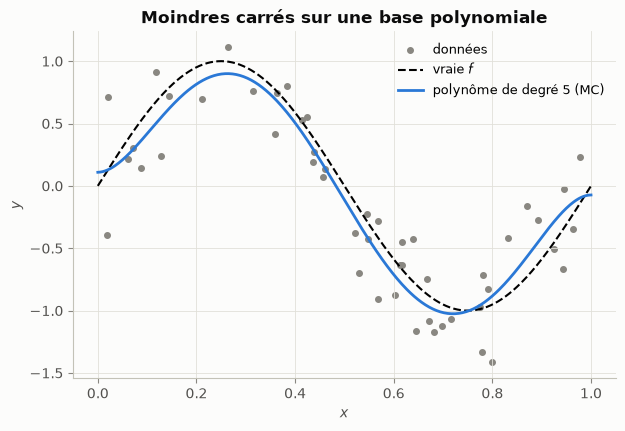

In [2]:
f_true = lambda x: np.sin(2 * np.pi * x)
N = 50
x = np.sort(rng.uniform(size=N))
y = f_true(x) + 0.3 * rng.normal(size=N)
x_plot = np.linspace(0, 1, 400)

# on utilise la variable recentrée t = 2x - 1 dans [-1, 1] : même famille de polynômes,
# mais matrice H mieux conditionnée numériquement
H = np.vander(2 * x - 1, 6, increasing=True)          # colonnes 1, t, ..., t^5
theta = c2.least_squares_fit(H, y, intercept=False)
fit_poly = np.vander(2 * x_plot - 1, 6, increasing=True) @ theta

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(x, y, s=16, color=GRAY, label="données")
ax.plot(x_plot, f_true(x_plot), color="k", lw=1.5, ls="--", label="vraie $f$")
ax.plot(x_plot, fit_poly, color=BLUE, label="polynôme de degré 5 (MC)")
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_title("Moindres carrés sur une base polynomiale")
ax.legend()
plt.show()

### Maximum de vraisemblance (éq. (2.33)-(2.36))

Un principe plus général que les moindres carrés est le **maximum de vraisemblance** :
si les $y_i$ sont indépendants de densité $\Pr_\theta(y)$, on maximise la
log-vraisemblance $L(\theta) = \sum_{i=1}^N \log\Pr_\theta(y_i)$ (éq. (2.33)), ce qui
revient à choisir le $\theta$ sous lequel les données observées sont les plus probables.

**Lien avec les moindres carrés.** Dans le modèle (2.29) avec $\varepsilon\sim\mathcal N(0,\sigma^2)$,
on a $\Pr(Y \mid X, \theta) = \mathcal N(f_\theta(X), \sigma^2)$ (éq. (2.34)). La densité
gaussienne vaut $\frac{1}{\sqrt{2\pi}\sigma}\exp\big(-\frac{(y - f_\theta(x))^2}{2\sigma^2}\big)$ ; en prenant le
logarithme et en sommant :
$$L(\theta) = -\frac N2\log(2\pi) - N\log\sigma - \frac{1}{2\sigma^2}\sum_{i=1}^N\big(y_i - f_\theta(x_i)\big)^2 \qquad \text{(éq. (2.35))}.$$
Seul le dernier terme dépend de $\theta$, avec un signe moins : maximiser $L$ revient à
**minimiser** $\mathrm{RSS}(\theta)$.

Vérifions-le numériquement : on maximise $L(\theta, \sigma)$ par un algorithme
d'optimisation générique et l'on compare aux moindres carrés.